# Лабораторная работа 2

Проваторов Роман Андреевич 409407 M3407

Выбран датасет с хакатона Академии ИИ "По страницам": https://ods.ai/competitions/nto25-26-hack

## Разведочный анализ данных

Датасет представляет собой набор данных о взаимодействиях пользователей с книжными изданиями.

In [55]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 80)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 12})


if Path("data").exists():
    DATA_DIR = Path("data")
else:
    raise FileNotFoundError("Data directory not found")

users = pd.read_csv(DATA_DIR / "users.csv")
interactions = pd.read_csv(DATA_DIR / "interactions.csv", parse_dates=["event_ts"])
editions = pd.read_csv(DATA_DIR / "editions.csv", low_memory=False)
authors = pd.read_csv(DATA_DIR / "authors.csv")
genres = pd.read_csv(DATA_DIR / "genres.csv")
book_genres = pd.read_csv(DATA_DIR / "book_genres.csv")

tables = {
    "users": users,
    "interactions": interactions,
    "editions": editions,
    "authors": authors,
    "genres": genres,
    "book_genres": book_genres,
}

overview = pd.DataFrame(
    {
        "Строк": {name: len(df) for name, df in tables.items()},
        "Столбцов": {name: df.shape[1] for name, df in tables.items()},
        "Поля": {name: ", ".join(df.columns) for name, df in tables.items()},
    }
).round({"Память, МБ": 2})

display(overview)
display(interactions.head(5))
display(editions.head(3))

,Строк,Столбцов,Поля
users,5067,3,"user_id, gender, age"
interactions,231210,5,"user_id, edition_id, event_type, rating, event_ts"
editions,134231,9,"edition_id, book_id, author_id, publication_year, age_restriction, language_..."
authors,36360,2,"author_id, author_name"
genres,586,2,"genre_id, genre_name"
book_genres,168251,2,"book_id, genre_id"


,user_id,edition_id,event_type,rating,event_ts
0,560,1012411658,2,6.0,2024-12-24 19:02:14
1,560,1008465904,2,6.0,2025-01-10 19:18:04
2,560,1001243738,2,10.0,2025-01-25 11:28:11
3,560,1009492501,2,8.0,2025-01-25 11:28:42
4,560,1000118974,2,8.0,2025-03-10 18:14:17


,edition_id,book_id,author_id,publication_year,age_restriction,language_id,publisher_id,title,description
0,1000000001,1093185,1.0,2000,18,119,9,Панорама времен,"Научный фантаст - тот, кто не стыдится первой части этого словосочетания, - ..."
1,1000000016,1548860,18.0,2005,16,119,1276,Развитие мышления: три пятидневных курса,"Талантливый ученый с мировым именем, изобретатель термина ""Lateral Thinking""..."
2,1000000020,20,21.0,2005,16,119,432,Вероника решает умереть,"Вторая изданная ""Софией"" книга Коэльо - совсем иная, чем знаменитый ""Алхимик..."


Таблица `interactions` является центральной: по `user_id` она связана с пользователями, а по `edition_id` - с изданиями. Издание относится к книге (`book_id`) и автору, а связь книги с жанрами имеет тип многие-ко-многим. Одна книга может иметь несколько изданий, поэтому `book_id` в `editions` закономерно повторяется.

### Целевая переменная

Рекомендуемый объект - конкретное книжное издание (`edition_id`) для конкретного пользователя (`user_id`). Требуется ранжировать издания, с которыми пользователь еще не взаимодействовал, по вероятности его будущего интереса.

### Качество данных

In [56]:
missing_report = pd.concat(
    [
        pd.DataFrame(
            {
                "Таблица": name,
                "Поле": df.columns,
                "Пропусков": df.isna().sum().values,
                "Доля, %": (100 * df.isna().mean()).values,
            }
        )
        for name, df in tables.items()
    ],
    ignore_index=True,
)
missing_report = missing_report[missing_report["Пропусков"] > 0].sort_values(
    ["Таблица", "Доля, %"], ascending=[True, False]
)
display(missing_report.round({"Доля, %": 2}))

duplicate_report = pd.Series(
    {
        "Полные дубликаты users": users.duplicated().sum(),
        "Полные дубликаты interactions": interactions.duplicated().sum(),
        "Полные дубликаты editions": editions.duplicated().sum(),
        "Дубликаты users.user_id": users["user_id"].duplicated().sum(),
        "Дубликаты editions.edition_id": editions["edition_id"].duplicated().sum(),
        "Дубликаты authors.author_id": authors["author_id"].duplicated().sum(),
        "Дубликаты genres.genre_id": genres["genre_id"].duplicated().sum(),
        "Дубликаты пар book_id–genre_id": book_genres.duplicated(
            ["book_id", "genre_id"]
        ).sum(),
        "Повторы одного события в ту же секунду": interactions.duplicated(
            ["user_id", "edition_id", "event_type", "event_ts"]
        ).sum(),
    },
    name="Количество",
).astype(int)
display(duplicate_report.to_frame())

,Таблица,Поле,Пропусков,"Доля, %"
18,authors,author_name,135,0.37
16,editions,description,8055,6.00
6,interactions,rating,105841,45.78
1,users,gender,171,3.37
2,users,age,90,1.78


,Количество
Полные дубликаты users,0
Полные дубликаты interactions,0
Полные дубликаты editions,0
Дубликаты users.user_id,0
Дубликаты editions.edition_id,0
Дубликаты authors.author_id,0
Дубликаты genres.genre_id,0
Дубликаты пар book_id–genre_id,0
Повторы одного события в ту же секунду,2


In [57]:
current_year = pd.Timestamp.now().year
blank_descriptions = editions["description"].fillna("").astype(str).str.strip().eq("").sum()

anomaly_report = pd.Series(
    {
        "Оценка у wishlist (не должна присутствовать)": (
            (interactions["event_type"] == 1) & interactions["rating"].notna()
        ).sum(),
        "read без оценки": (
            (interactions["event_type"] == 2) & interactions["rating"].isna()
        ).sum(),
        "Оценка вне диапазона 1–10": (
            interactions["rating"].notna() & ~interactions["rating"].between(1, 10)
        ).sum(),
        "Некорректный тип события": (~interactions["event_type"].isin([1, 2])).sum(),
        "Некорректная временная метка": interactions["event_ts"].isna().sum(),
        "Пустое описание": blank_descriptions,
    },
    name="Количество",
).astype(int)
display(anomaly_report.to_frame())

,Количество
Оценка у wishlist (не должна присутствовать),0
read без оценки,21290
Оценка вне диапазона 1–10,0
Некорректный тип события,0
Некорректная временная метка,0
Пустое описание,8067


### Статистики взаимодействий

При расчете плотности одна наблюдаемая ячейка соответствует уникальной паре `user_id–edition_id`. Повторные события одной пары не должны искусственно увеличивать плотность матрицы.

In [58]:
unique_pairs = interactions[["user_id", "edition_id"]].drop_duplicates().shape[0]
n_users = users["user_id"].nunique()
n_catalog_items = editions["edition_id"].nunique()
n_seen_items = interactions["edition_id"].nunique()
density = unique_pairs / (n_users * n_catalog_items)

recsys_summary = pd.Series(
    {
        "Пользователей": n_users,
        "Изданий в каталоге": n_catalog_items,
        "Изданий с взаимодействиями": n_seen_items,
        "Событий": len(interactions),
        "Уникальных пар пользователь – издание": unique_pairs,
        "Начало периода": interactions["event_ts"].min(),
        "Конец периода": interactions["event_ts"].max(),
        "Плотность матрицы, %": 100 * density,
        "Доля изданий без взаимодействий, %": 100 * (1 - n_seen_items / n_catalog_items),
    },
    name="Значение",
)
display(recsys_summary.to_frame())

event_stats = (
    interactions.assign(
        Событие=interactions["event_type"].map({1: "wishlist", 2: "read"})
    )
    .groupby("Событие", observed=True)
    .agg(Событий=("event_type", "size"), Оценок=("rating", "count"))
)
event_stats["Доля событий, %"] = 100 * event_stats["Событий"] / len(interactions)
event_stats["Покрытие оценками, %"] = 100 * event_stats["Оценок"] / event_stats["Событий"]
display(event_stats.round(2))

rating_stats = interactions["rating"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
).rename("Оценка")
display(rating_stats.to_frame().round(2))

,Значение
Пользователей,5067
Изданий в каталоге,134231
Изданий с взаимодействиями,74528
Событий,231210
Уникальных пар пользователь – издание,231038
Начало периода,2024-10-14 18:48:56
Конец периода,2025-04-12 12:44:23
"Плотность матрицы, %",0.033969
"Доля изданий без взаимодействий, %",44.477803


,Событий,Оценок,"Доля событий, %","Покрытие оценками, %"
Событие,,,,
read,146659,125369,63.43,85.48
wishlist,84551,0,36.57,0.00


,Оценка
count,125369.00
mean,8.29
std,1.78
min,1.00
10%,6.00
25%,8.00
50%,8.00
75%,10.00
90%,10.00
max,10.00


In [59]:
user_activity = interactions.groupby("user_id").size().sort_values(ascending=False)
item_popularity = interactions.groupby("edition_id").size().sort_values(ascending=False)

activity_quantiles = pd.DataFrame(
    {
        "Событий на пользователя": user_activity.quantile(
            [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
        ),
        "Событий на издание с историей": item_popularity.quantile(
            [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
        ),
    }
)
activity_quantiles.index.name = "Квантиль"
display(activity_quantiles.round(2))

concentration = {}
for share in [0.01, 0.05, 0.10, 0.20]:
    top_n = max(1, int(np.ceil(len(item_popularity) * share)))
    concentration[f"Верхние {share:.0%} изданий"] = (
        100 * item_popularity.iloc[:top_n].sum() / item_popularity.sum()
    )
display(pd.Series(concentration, name="Доля всех событий, %").to_frame().round(2))

,Событий на пользователя,Событий на издание с историей
Квантиль,,
0.00,5.00,1.0
0.25,16.00,1.0
0.50,30.00,1.0
0.75,57.00,2.0
0.90,102.00,6.0
0.95,143.00,11.0
0.99,234.34,33.0
1.00,290.00,378.0


,"Доля всех событий, %"
Верхние 1% изданий,20.40
Верхние 5% изданий,43.19
Верхние 10% изданий,55.72
Верхние 20% изданий,68.33


### Визуализация распределений

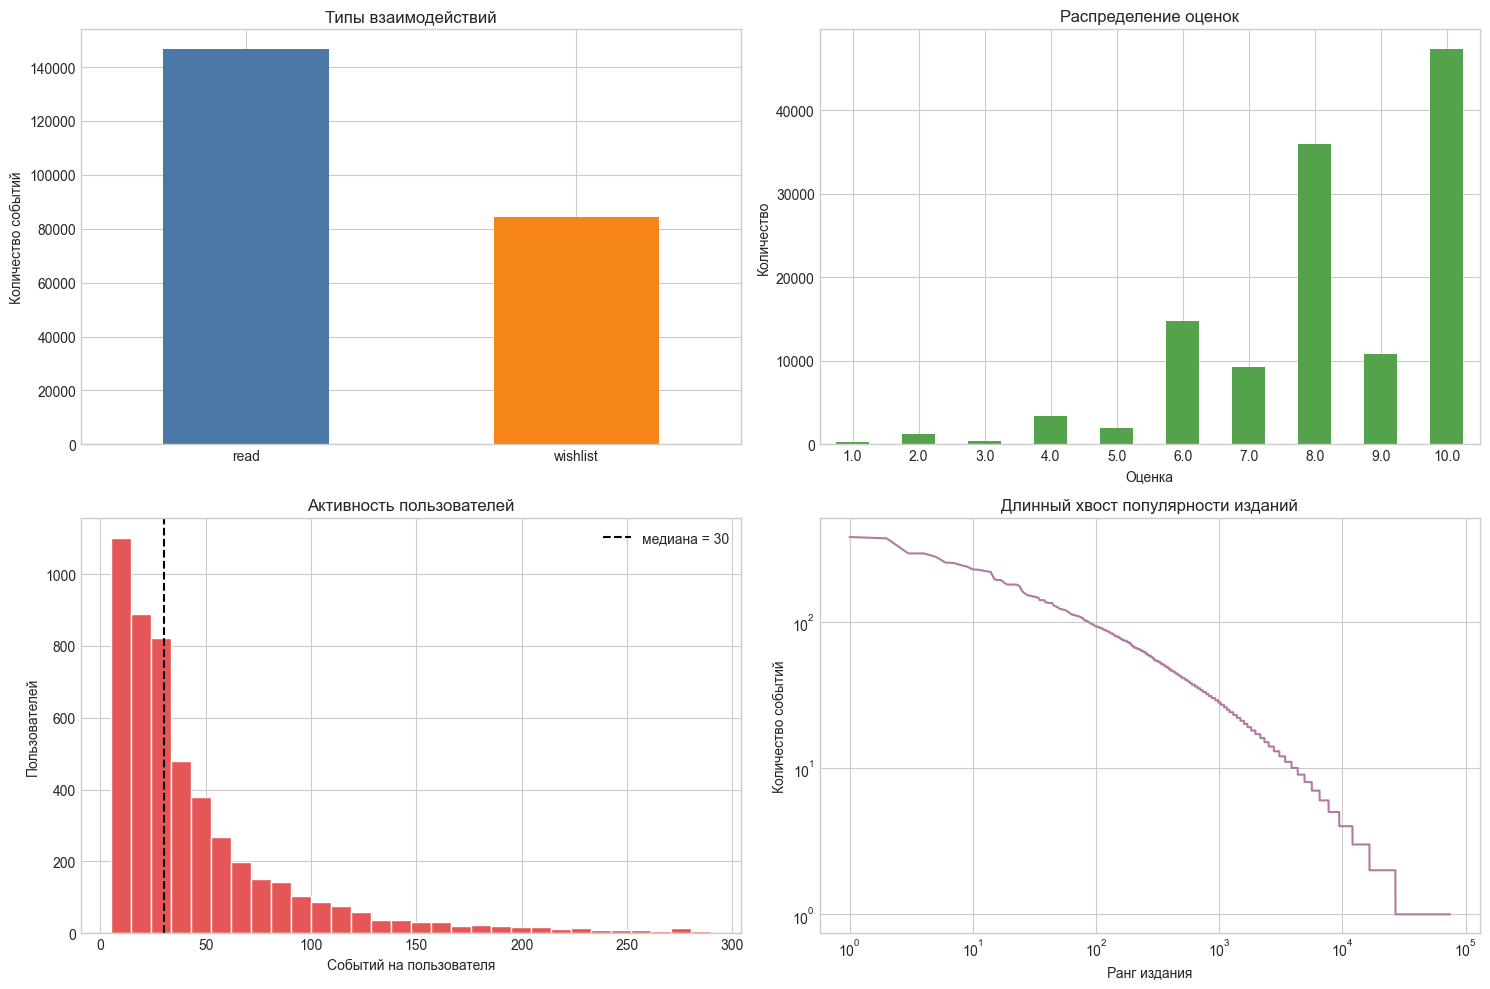

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

event_counts = interactions["event_type"].map({1: "wishlist", 2: "read"}).value_counts()
event_counts.plot.bar(ax=axes[0, 0], color=["#4C78A8", "#F58518"], rot=0)
axes[0, 0].set(title="Типы взаимодействий", xlabel="", ylabel="Количество событий")

rating_counts = interactions["rating"].value_counts().sort_index()
rating_counts.plot.bar(ax=axes[0, 1], color="#54A24B", rot=0)
axes[0, 1].set(title="Распределение оценок", xlabel="Оценка", ylabel="Количество")

axes[1, 0].hist(user_activity, bins=30, color="#E45756", edgecolor="white")
axes[1, 0].axvline(user_activity.median(), color="black", ls="--", label=f"медиана = {user_activity.median():.0f}")
axes[1, 0].set(title="Активность пользователей", xlabel="Событий на пользователя", ylabel="Пользователей")
axes[1, 0].legend()

ranks = np.arange(1, len(item_popularity) + 1)
axes[1, 1].loglog(ranks, item_popularity.values, color="#B279A2", lw=1.5)
axes[1, 1].set(title="Длинный хвост популярности изданий", xlabel="Ранг издания", ylabel="Количество событий")

plt.tight_layout()
plt.show()

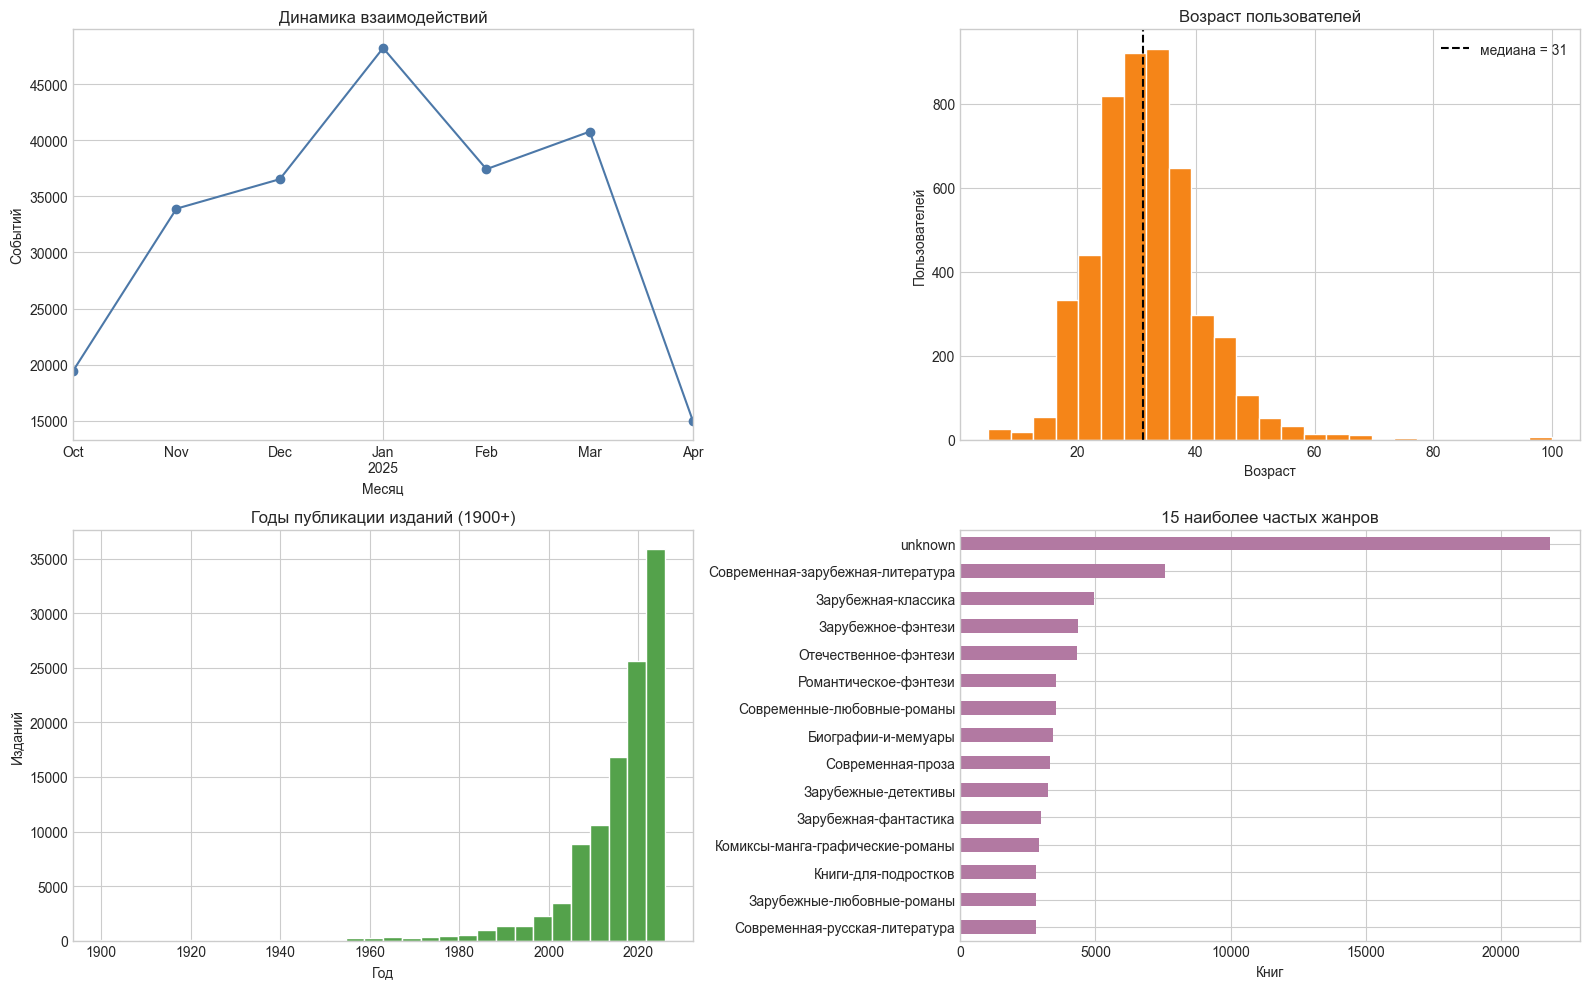

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

monthly_events = interactions.set_index("event_ts").resample("MS").size()
monthly_events.plot(ax=axes[0, 0], marker="o", color="#4C78A8")
axes[0, 0].set(title="Динамика взаимодействий", xlabel="Месяц", ylabel="Событий")

axes[0, 1].hist(users["age"].dropna(), bins=25, color="#F58518", edgecolor="white")
axes[0, 1].axvline(users["age"].median(), color="black", ls="--", label=f"медиана = {users['age'].median():.0f}")
axes[0, 1].set(title="Возраст пользователей", xlabel="Возраст", ylabel="Пользователей")
axes[0, 1].legend()

valid_years = editions.loc[editions["publication_year"].between(1900, current_year), "publication_year"]
axes[1, 0].hist(valid_years, bins=30, color="#54A24B", edgecolor="white")
axes[1, 0].set(title="Годы публикации изданий (1900+)", xlabel="Год", ylabel="Изданий")

genre_counts = (
    book_genres.merge(genres, on="genre_id", how="left")["genre_name"]
    .value_counts()
    .head(15)
    .sort_values()
)
genre_counts.plot.barh(ax=axes[1, 1], color="#B279A2")
axes[1, 1].set(title="15 наиболее частых жанров", xlabel="Книг", ylabel="")

plt.tight_layout()
plt.show()

### Предобработка

In [62]:
users_clean = users.copy()
editions_clean = editions.copy()
authors_clean = authors.copy()
genres_clean = genres.copy()
book_genres_clean = book_genres.copy()

users_clean[["gender", "age"]] = users_clean[["gender", "age"]].astype("Int64")
authors_clean["author_name"] = authors_clean["author_name"].astype("string").str.strip().replace("", pd.NA)
genres_clean["genre_name"] = genres_clean["genre_name"].astype("string").str.strip().replace("", pd.NA)
for column in ["title", "description"]:
    editions_clean[column] = editions_clean[column].astype("string").str.strip().replace("", pd.NA)

invalid_year = ~editions_clean["publication_year"].between(1450, current_year)
editions_clean.loc[invalid_year, "publication_year"] = pd.NA
for column in ["author_id", "publication_year", "language_id", "publisher_id"]:
    editions_clean[column] = editions_clean[column].astype("Int64")
for column in ["language_id", "publisher_id"]:
    editions_clean.loc[editions_clean[column].eq(0), column] = pd.NA

event_key = ["user_id", "edition_id", "event_type", "event_ts"]
interactions_clean = (
    interactions.groupby(event_key, as_index=False, dropna=False)["rating"].mean()
    .sort_values(["event_ts", "user_id", "edition_id"])
    .reset_index(drop=True)
)

cleaning_report = pd.Series(
    {
        "Удалено повторов одного события": len(interactions) - len(interactions_clean),
        "Некорректных годов заменено на NA": int(invalid_year.sum()),
        "Нулевых language_id заменено на NA": int((editions["language_id"] == 0).sum()),
        "Нулевых publisher_id заменено на NA": int((editions["publisher_id"] == 0).sum()),
        "Пустых описаний после нормализации": int(editions_clean["description"].isna().sum()),
    },
    name="Количество",
)
display(cleaning_report.to_frame())

,Количество
Удалено повторов одного события,2
Некорректных годов заменено на NA,24388
Нулевых language_id заменено на NA,8889
Нулевых publisher_id заменено на NA,31011
Пустых описаний после нормализации,8067


### Выводы

1. Датасет содержит 231 210 взаимодействий 5 067 пользователей со 134 231 изданием. Основной целевой сигнал - будущее событие `wishlist` или `read` для пары `user_id - edition_id`, оценка служит дополнительным явным сигналом.
2. Матрица взаимодействий разрежена на 99,966%, события сильно смещены к популярным изданиям, а 44,48% каталога не имеет истории. Поэтому модели должны учитывать длинный хвост и холодный старт, используя метаданные книг наряду с коллаборативным сигналом.
3. Ключи и связи между таблицами корректны. Основные проблемы качества - неизвестные годы публикации, пустые описания и небольшое число повторных событий. Они обработаны в очищенных копиях без удаления естественных выбросов активности и популярности.

## Методы формирования рекомендаций

Выбраны три метода из разных семейств: MostPop, UserKNN и ALS для неявной обратной связи. Такой набор позволяет сравнить простой baseline с двумя персонализированными подходами и проверить, дает ли учет сходства пользователей или скрытых факторов прирост качества на разреженных данных.

Все методы используют одинаковую бинарную матрицу взаимодействий $R$: $R_{ui}=1$, если пользователь добавлял издание в `wishlist` или читал его, и $R_{ui}=0$ при отсутствии наблюдаемого взаимодействия. Уже известные пользователю издания исключаются из рекомендаций.

In [63]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

user_ids = np.sort(users_clean["user_id"].unique())
item_ids = np.sort(editions_clean["edition_id"].unique())
user_index = pd.Index(user_ids, name="user_id")
item_index = pd.Index(item_ids, name="edition_id")

positive_pairs = interactions_clean[["user_id", "edition_id"]].drop_duplicates()
row_indices = user_index.get_indexer(positive_pairs["user_id"])
column_indices = item_index.get_indexer(positive_pairs["edition_id"])

R = csr_matrix(
    (
        np.ones(len(positive_pairs), dtype=np.float32),
        (row_indices, column_indices),
    ),
    shape=(len(user_index), len(item_index)),
)

matrix_info = pd.Series(
    {
        "Пользователей": R.shape[0],
        "Изданий": R.shape[1],
        "Ненулевых пар": R.nnz,
        "Плотность, %": 100 * R.nnz / (R.shape[0] * R.shape[1]),
    },
    name="Значение",
)
display(matrix_info.to_frame())

,Значение
Пользователей,5067.000000
Изданий,134231.000000
Ненулевых пар,231038.000000
"Плотность, %",0.033969


### MostPop

Метод ранжирует издания по числу уникальных пользователей, взаимодействовавших с ними:

$$score(i)=\sum_u R_{ui}.$$

MostPop выбран в качестве baseline

### UserKNN

Для пользователя находятся $K=50$ ближайших соседей по косинусному сходству бинарных векторов взаимодействий:

$$sim(u,v)=\frac{R_u R_v^T}{\lVert R_u\rVert_2\lVert R_v\rVert_2}.$$

Оценка издания равна взвешенной сумме взаимодействий соседей:

$$score(u,i)=\frac{\sum_{v\in N_K(u)}sim(u,v)R_{vi}}{\sum_{v\in N_K(u)}sim(u,v)}.$$

UserKNN подходит для данной задачи, поскольку у каждого пользователя есть история wishlist и read, по которой можно найти читателей с похожими интересами. Метод работает непосредственно с разреженной бинарной матрицей, не требует заполнения пропусков в метаданных и остается интерпретируемым: рекомендацию можно объяснить предпочтениями похожих пользователей.

### ALS

Для бинарных неявных данных задаются предпочтение $p_{ui}=\mathbb{1}[R_{ui}>0]$ и уверенность $c_{ui}=1+\alpha R_{ui}$. ALS подбирает векторы пользователей $x_u$ и изданий $y_i$, минимизируя взвешенную ошибку:

$$\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\lVert X\rVert_F^2+\lVert Y\rVert_F^2).$$

ALS специально адаптирован к неявной обратной связи и эффективно использует разреженную матрицу взаимодействий. В отличие от UserKNN, он выявляет скрытые факторы интересов и может находить непрямые зависимости между пользователями и изданиями, поэтому представляет более сложную персонализированную модель для сравнения.

In [64]:
def top_k_unseen(scores, seen_indices, k):
    scores = np.asarray(scores, dtype=np.float64).ravel().copy()
    scores[np.asarray(seen_indices, dtype=int)] = -np.inf
    k = min(k, int(np.isfinite(scores).sum()))
    if k == 0:
        return np.array([], dtype=int), np.array([], dtype=float)
    candidates = np.argpartition(scores, -k)[-k:]
    candidates = candidates[np.argsort(scores[candidates])[::-1]]
    return candidates, scores[candidates]


class MostPopRecommender:
    def fit(self, matrix):
        self.R = matrix.tocsr()
        self.popularity = np.asarray(self.R.sum(axis=0)).ravel()
        return self

    def recommend(self, user_idx, k=10):
        return top_k_unseen(self.popularity, self.R[user_idx].indices, k)


class UserKNNRecommender:
    def __init__(self, n_neighbors=50):
        self.n_neighbors = n_neighbors

    def fit(self, matrix):
        self.R = matrix.tocsr()
        self.popularity = np.asarray(self.R.sum(axis=0)).ravel()
        self.active_items = self.popularity > 0
        self.model = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1)
        self.model.fit(self.R)
        return self

    def recommend(self, user_idx, k=10):
        if self.R[user_idx].nnz == 0:
            return top_k_unseen(self.popularity, [], k)

        n_query = min(self.n_neighbors + 1, self.R.shape[0])
        distances, neighbors = self.model.kneighbors(self.R[user_idx], n_neighbors=n_query)
        neighbors = neighbors.ravel()
        similarities = 1 - distances.ravel()
        keep = (neighbors != user_idx) & (similarities > 0)
        neighbors, similarities = neighbors[keep], similarities[keep]

        if len(neighbors) == 0:
            return top_k_unseen(self.popularity, self.R[user_idx].indices, k)

        scores = np.asarray(self.R[neighbors].T.dot(similarities)).ravel()
        scores /= similarities.sum()
        scores[~self.active_items] = -np.inf
        return top_k_unseen(scores, self.R[user_idx].indices, k)


class ALSRecommender:
    def __init__(
        self, n_factors=32, n_iterations=5, alpha=20.0,
        regularization=0.1, random_state=42,
    ):
        self.n_factors = n_factors
        self.n_iterations = n_iterations
        self.alpha = alpha
        self.regularization = regularization
        self.random_state = random_state

    def _least_squares_step(self, interactions, fixed_factors):
        result = np.zeros((interactions.shape[0], self.n_factors), dtype=np.float32)
        gram = fixed_factors.T @ fixed_factors
        regularizer = self.regularization * np.eye(self.n_factors, dtype=np.float32)

        for entity_idx in range(interactions.shape[0]):
            start, end = interactions.indptr[entity_idx : entity_idx + 2]
            related = interactions.indices[start:end]
            if len(related) == 0:
                continue

            factors = fixed_factors[related]
            confidence_extra = self.alpha * interactions.data[start:end]
            lhs = gram + (factors.T * confidence_extra) @ factors + regularizer
            rhs = factors.T @ (1.0 + confidence_extra)
            result[entity_idx] = np.linalg.solve(lhs, rhs)

        return result

    def fit(self, matrix):
        self.R = matrix.astype(np.float32).tocsr()
        self.R_T = self.R.T.tocsr()
        self.popularity = np.asarray(self.R.sum(axis=0)).ravel()
        self.active_items = np.diff(self.R_T.indptr) > 0

        rng = np.random.default_rng(self.random_state)
        self.item_factors = np.zeros(
            (self.R.shape[1], self.n_factors), dtype=np.float32
        )
        self.item_factors[self.active_items] = rng.normal(
            0, 0.01, (self.active_items.sum(), self.n_factors)
        )

        for _ in range(self.n_iterations):
            self.user_factors = self._least_squares_step(self.R, self.item_factors)
            self.item_factors = self._least_squares_step(self.R_T, self.user_factors)

        return self

    def recommend(self, user_idx, k=10):
        if self.R[user_idx].nnz == 0:
            return top_k_unseen(self.popularity, [], k)
        scores = self.user_factors[user_idx] @ self.item_factors.T
        scores[~self.active_items] = -np.inf
        return top_k_unseen(scores, self.R[user_idx].indices, k)

## Метрики качества рекомендаций

Для сравнения методов выбраны четыре метрики: NDCG, Coverage, ILD и Novelty

- **NDCG@K** выбрана как метрика качества ранжирования: она показывает, попали ли релевантные издания в Top-K, и сильнее поощряет их появление в начале списка, что соответствует сценарию выдачи рекомендаций пользователю.
- **Coverage@K** выбрана для контроля широты использования каталога: в данных 44,48% изданий не имеют взаимодействий, поэтому важно выявить модели, которые ограничиваются небольшим набором хитов.
- **ILD@K** выбрана для оценки разнообразия внутри списка: жанры позволяют проверить, не состоит ли выдача из слишком похожих книг и не сужает ли она круг интересов пользователя.
- **Novelty@K** выбрана для контроля смещения к популярным объектам: она показывает, способна ли модель рекомендовать менее известные издания из длинного хвоста каталога.

In [65]:
from itertools import combinations

def catalog_coverage_at_k(recommendations_by_user, catalog_size, k=20):
    if catalog_size <= 0:
        return np.nan
    recommended_items = {
        item_id
        for recommendations in recommendations_by_user.values()
        for item_id in list(recommendations)[:k]
    }
    return len(recommended_items) / catalog_size

def ndcg_at_k(recommendations, relevant_items, k=20):
    relevant_items = set(relevant_items)
    if not relevant_items:
        return np.nan
    gains = np.array(
        [item_id in relevant_items for item_id in list(recommendations)[:k]],
        dtype=float,
    )
    discounts = np.log2(np.arange(2, len(gains) + 2))
    dcg = np.sum(gains / discounts)

    ideal_gains = np.ones(min(len(relevant_items), k), dtype=float)
    idcg = np.sum(ideal_gains / np.log2(np.arange(2, len(ideal_gains) + 2)))
    return dcg / idcg

def ild_at_k(recommendations, item_genres, k=20):
    genre_sets = [
        set(item_genres.get(item_id, set()))
        for item_id in list(recommendations)[:k]
    ]
    genre_sets = [genres for genres in genre_sets if genres]
    if len(genre_sets) < 2:
        return np.nan

    distances = []
    for left, right in combinations(genre_sets, 2):
        distances.append(1 - len(left & right) / len(left | right))
    return float(np.mean(distances))

def novelty_at_k(recommendations, item_user_counts, n_users, k=20):
    recommended = list(recommendations)[:k]
    if not recommended:
        return np.nan
    counts = np.array(
        [item_user_counts.get(item_id, 0) for item_id in recommended],
        dtype=float,
    )
    if np.any(counts <= 0):
        return np.inf
    return float(np.mean(np.log2(n_users / counts)))

## Обучение и сравнение моделей

Используется временное пользовательское разбиение Leave-One-Out: последнее уникальное взаимодействие каждого пользователя отложено в тест, остальные взаимодействия образуют обучающую выборку. Рекомендации строятся по полному каталогу, при этом уже просмотренные в обучении издания исключаются.

In [66]:
pair_history = (
    interactions_clean.groupby(["user_id", "edition_id"], as_index=False)
    .agg(event_ts=("event_ts", "max"))
    .sort_values(["user_id", "event_ts", "edition_id"])
    .reset_index(drop=True)
)

interactions_per_user = pair_history.groupby("user_id")["edition_id"].transform("size")
test_indices = pair_history[interactions_per_user >= 2].groupby("user_id").tail(1).index
test_pairs = pair_history.loc[test_indices, ["user_id", "edition_id", "event_ts"]].copy()
train_pairs = pair_history.drop(index=test_indices).copy()

train_rows = user_index.get_indexer(train_pairs["user_id"])
train_columns = item_index.get_indexer(train_pairs["edition_id"])
R_train = csr_matrix(
    (np.ones(len(train_pairs), dtype=np.float32), (train_rows, train_columns)),
    shape=(len(user_index), len(item_index)),
)

active_train_items = set(train_pairs["edition_id"].unique())
warm_test_pairs = test_pairs[test_pairs["edition_id"].isin(active_train_items)].copy()
cold_test_pairs = test_pairs[~test_pairs["edition_id"].isin(active_train_items)].copy()
test_targets = warm_test_pairs.set_index("user_id")["edition_id"].to_dict()
evaluation_user_ids = warm_test_pairs["user_id"].to_numpy()
evaluation_user_indices = user_index.get_indexer(evaluation_user_ids)

split_summary = pd.Series(
    {
        "Взаимодействий в обучении": len(train_pairs),
        "Пользователей в тесте": len(test_pairs),
        "Warm-start пользователей": len(warm_test_pairs),
        "Cold-start тестовых изданий": len(cold_test_pairs),
        "Активных изданий в обучении": R_train.getnnz(axis=0).astype(bool).sum(),
    },
    name="Количество",
)
display(split_summary.to_frame())

,Количество
Взаимодействий в обучении,225971
Пользователей в тесте,5067
Warm-start пользователей,4104
Cold-start тестовых изданий,963
Активных изданий в обучении,73576


In [67]:
TOP_K = 20
models = {
    "MostPop": MostPopRecommender(),
    "UserKNN": UserKNNRecommender(n_neighbors=50),
    "ALS": ALSRecommender(
        n_factors=32, n_iterations=5, alpha=20.0,
        regularization=0.1, random_state=42,
    ),
}

for model_name, model in models.items():
    model.fit(R_train)

def generate_recommendations(model, user_ids, user_indices, k=20, batch_size=64):
    recommendations = {}

    if isinstance(model, UserKNNRecommender):
        n_query = min(model.n_neighbors + 1, model.R.shape[0])
        distances, neighbors = model.model.kneighbors(
            model.R[user_indices], n_neighbors=n_query
        )
        for user_id, user_idx, user_distances, user_neighbors in zip(
            user_ids, user_indices, distances, neighbors
        ):
            similarities = 1 - user_distances
            keep = (user_neighbors != user_idx) & (similarities > 0)
            neighbor_ids = user_neighbors[keep]
            similarities = similarities[keep]
            if len(neighbor_ids) == 0:
                item_positions, _ = top_k_unseen(
                    model.popularity, model.R[user_idx].indices, k
                )
            else:
                scores = np.asarray(model.R[neighbor_ids].T.dot(similarities)).ravel()
                scores[~model.active_items] = -np.inf
                item_positions, _ = top_k_unseen(
                    scores, model.R[user_idx].indices, k
                )
            recommendations[int(user_id)] = item_index.take(item_positions).tolist()
        return recommendations

    if isinstance(model, ALSRecommender):
        for start in range(0, len(user_indices), batch_size):
            batch_indices = user_indices[start : start + batch_size]
            batch_scores = model.user_factors[batch_indices] @ model.item_factors.T
            batch_scores[:, ~model.active_items] = -np.inf
            for row, user_idx in enumerate(batch_indices):
                batch_scores[row, model.R[user_idx].indices] = -np.inf
            top_positions = np.argpartition(batch_scores, -k, axis=1)[:, -k:]
            top_scores = np.take_along_axis(batch_scores, top_positions, axis=1)
            order = np.argsort(top_scores, axis=1)[:, ::-1]
            top_positions = np.take_along_axis(top_positions, order, axis=1)
            for user_id, positions in zip(user_ids[start : start + batch_size], top_positions):
                recommendations[int(user_id)] = item_index.take(positions).tolist()
        return recommendations

    for user_id, user_idx in zip(user_ids, user_indices):
        item_positions, _ = model.recommend(user_idx, k=k)
        recommendations[int(user_id)] = item_index.take(item_positions).tolist()
    return recommendations


recommendations_by_model = {}
for model_name, model in models.items():
    recommendations_by_model[model_name] = generate_recommendations(
        model, evaluation_user_ids, evaluation_user_indices, k=TOP_K
    )

,NDCG@20,Coverage@20,ILD@20,Novelty@20
Модель,,,,
MostPop,0.011700,0.000300,0.910500,4.484200
UserKNN,0.049200,0.036000,0.880700,5.932900
ALS,0.030600,0.012900,0.861900,5.743000


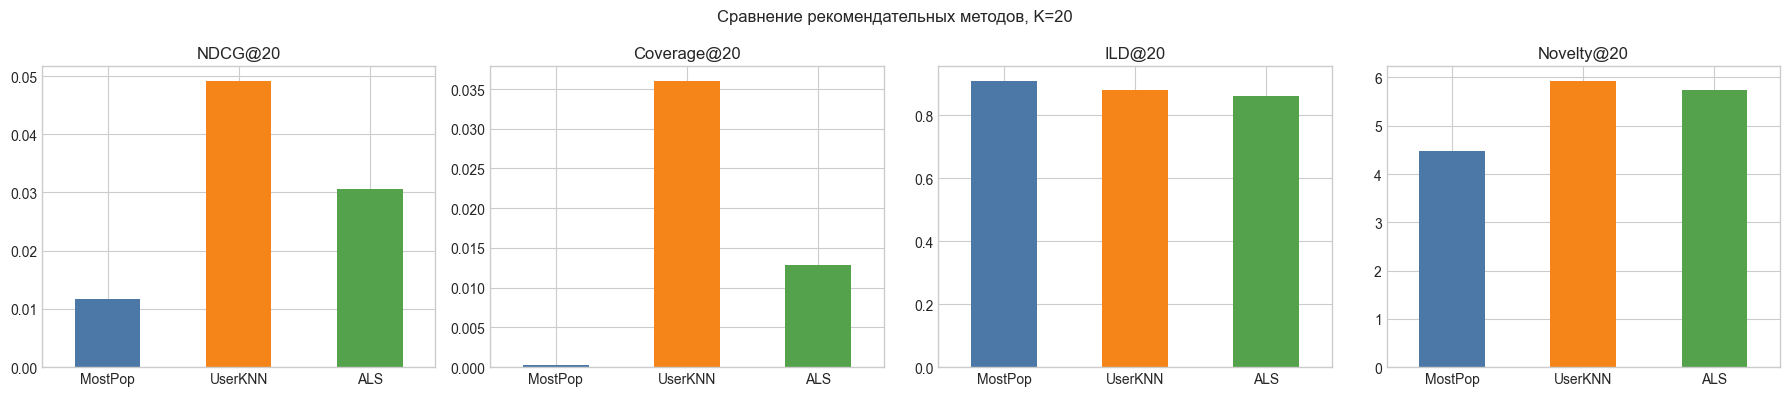

In [68]:
item_genres = (
    editions_clean[["edition_id", "book_id"]]
    .merge(book_genres_clean, on="book_id", how="left")
    .dropna(subset=["genre_id"])
    .groupby("edition_id")["genre_id"]
    .agg(lambda values: frozenset(values.astype(int)))
    .to_dict()
)
train_item_user_counts = train_pairs.groupby("edition_id")["user_id"].nunique().to_dict()
n_train_users = int((R_train.getnnz(axis=1) > 0).sum())

metric_rows = []
for model_name, user_recommendations in recommendations_by_model.items():
    ndcg_values = [
        ndcg_at_k(items, {test_targets[user_id]}, k=TOP_K)
        for user_id, items in user_recommendations.items()
    ]
    ild_values = [
        ild_at_k(items, item_genres, k=TOP_K)
        for items in user_recommendations.values()
    ]
    novelty_values = [
        novelty_at_k(items, train_item_user_counts, n_train_users, k=TOP_K)
        for items in user_recommendations.values()
    ]
    metric_rows.append(
        {
            "Модель": model_name,
            "NDCG@20": np.nanmean(ndcg_values),
            "Coverage@20": catalog_coverage_at_k(
                user_recommendations, catalog_size=len(item_index), k=TOP_K
            ),
            "ILD@20": np.nanmean(ild_values),
            "Novelty@20": np.nanmean(novelty_values),
        }
    )

metrics_table = pd.DataFrame(metric_rows).set_index("Модель")
display(metrics_table.round(4).style.highlight_max(axis=0, color="#6abb4d"))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for metric, axis in zip(metrics_table.columns, axes):
    metrics_table[metric].plot.bar(ax=axis, color=["#4C78A8", "#F58518", "#54A24B"], rot=0)
    axis.set_title(metric)
    axis.set_xlabel("")
    axis.set_ylim(bottom=0)
plt.suptitle("Сравнение рекомендательных методов, K=20")
plt.tight_layout()
plt.show()

### Интерпретация результатов

- UserKNN показал лучший результат: максимальные NDCG@20 = 0,0492, Coverage@20 = 0,0360 и Novelty@20 = 5,9329. Значит, соседские предпочтения лучше находят будущие взаимодействия и задействуют более широкий и менее популярный набор изданий.
- MostPop имеет минимальные NDCG, Coverage и Novelty, поскольку почти всем пользователям показывает одни и те же популярные издания. Максимальный ILD@20 = 0,9105 означает лишь жанровую разнородность этого общего списка.

## Предложения по улучшению рекомендаций

1. Настроить гиперпараметры UserKNN и ALS по отдельной временной валидационной выборке, оптимизируя NDCG@20 и одновременно контролируя Coverage, ILD и Novelty.
2. Добавить гибридную контентную модель по жанрам, авторам, языку и тексту описания. Она позволит рекомендовать новые издания без истории взаимодействий и обработать 963 cold-start случаев, исключенных из текущего сравнения.
3. Выполнить переранжирование Top-N кандидатов: штрафовать слишком похожие и чрезмерно популярные издания, чтобы повысить разнообразие, новизну и покрытие при ограничении на допустимое снижение NDCG.
4. Использовать силу сигнала: различать `wishlist` и `read`, учитывать оценку и давность события вместо одинакового бинарного веса для всех взаимодействий.